# Fase B · Limpieza y normalización. Siniestralidad vial en Cali 2016–2024

Proyecto 2 y 3 · Grupo DatosSinCiencia

**Objetivo:** convertir el CSV original en una tabla sin faltantes, con las variables codificadas, transformadas y
escaladas, para entrenar los modelos de la Fase C.

Entrada: `siniestralidad_2016_2024.csv` (ruta en `.env`). Salida: `datos_limpios.parquet`.

| Paso | Qué se hace | ¿Aprende de los datos? |
|---|---|---|
| 1 | Diagnóstico: nulos, duplicados, texto inconsistente, tipos, outliers | No aplica |
| 2 | Limpieza estructural: faltantes `"."` → `NaN`, fila vacía, duplicados, columna repetida | No |
| 3 | Normalización de texto y agrupación de categorías | No |
| 4 | Conversión de tipos y variables derivadas (fecha, vehículos, tipo de vía) | No |
| 5 | Outliers: detección con IQR y Z-score | No |
| 6 | Split train/test 80/20 estratificado | No aplica |
| 7 | Imputación de nulos (mediana, moda, categoría constante) | Sí, solo con train |
| 8 | Transformación de variables sesgadas (log vs. Yeo-Johnson) | Sí, solo con train |
| 9 | Encoding: Ordinal y One-Hot | No |
| 10 | Escalado: Z-score y Min-Max | Sí, solo con train |
| 11 | Validación y guardado del parquet | No aplica |

> Regla contra la fuga de datos (data leakage): todo valor que se calcula a partir del dataset (la mediana o la moda para
> imputar, la media y la desviación para escalar) sale solo de las filas de entrenamiento y después se aplica a train y
> test. Por eso el split va en el paso 6, antes de imputar y escalar. La partición queda guardada en la columna `SPLIT`
> para que la Fase C use la misma.

In [1]:
import os
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OrdinalEncoder, PowerTransformer, StandardScaler

load_dotenv()      # lee la ruta del CSV desde el archivo .env (ver .env.example)
RUTA_CSV = os.getenv("RUTA_CSV", "../siniestralidad_2016_2024.csv")
SEMILLA = 42

crudo = pd.read_csv(RUTA_CSV, sep=";", encoding="latin-1", dtype=str)
print(f"Dataset original: {len(crudo):,} filas × {crudo.shape[1]} columnas")
crudo.head()

Dataset original: 371,003 filas × 10 columnas


,Código,Fecha,Tipo confirmado,Dirección reporte,Tipo clase de accidente,Tipo clase de accidente.1,Tipo confirmado.1,Medio de reporte,Numero vehículos,Tipo de vehículos implicados
0,96159,1/01/2016,Solo daños,Carrera 56 Con Calle 1 A,.,.,Solo Da?os,RADIO,2,MOTOCICLETA
1,96160,1/01/2016,Negativo,Calle 72 O Con Carrera 28 H,.,.,Negativo,RADIO,.,.
2,96161,1/01/2016,Con lesionado,Carrera 94 Con Calle 4 C,ATROPELLO,ATROPELLO,Por Atropello,TELEF?NICO 127,2,MOTOCICLETA
3,96162,1/01/2016,Con lesionado,Carrera 8 A Con Calle 44,VOLCAMIENTO,VOLCAMIENTO,Por Volcamiento,RADIO,1,MOTOCICLETA
4,96163,1/01/2016,Negativo,Carrera 28 H Con Calle 72 M,.,.,Negativo,TELEF?NICO 127,.,.


## Paso 1. Diagnóstico

Antes de cambiar nada se mide cada problema de calidad. En este archivo los faltantes vienen marcados con un punto `"."`
y no como celdas vacías; el conteo incluye ambos casos.

### 1.1 Nulos y duplicados

In [2]:
sin_dato = crudo.isna() | (crudo == ".")
diagnostico = pd.DataFrame({
    "nulos_reales": crudo.isna().sum(),
    "marcados_con_punto": (crudo == ".").sum(),
    "% sin dato": (sin_dato.mean() * 100).round(1),
    "valores_unicos": crudo.nunique(),
}).sort_values("% sin dato", ascending=False)
print(diagnostico)

print(f"\nFilas completamente vacías: {sin_dato.all(axis=1).sum()}")
print(f"Filas duplicadas (exactas): {crudo.duplicated().sum()}")
print(f"Códigos de reporte repetidos: {crudo['Código'].dropna().duplicated().sum()}")
print(f"¿'Tipo clase de accidente' y 'Tipo clase de accidente.1' son idénticas? "
      f"{crudo['Tipo clase de accidente'].equals(crudo['Tipo clase de accidente.1'])}")

                              nulos_reales  marcados_con_punto  % sin dato  \
Tipo clase de accidente                  1              325257        87.7   
Tipo clase de accidente.1                1              325257        87.7   
Medio de reporte                         0              288099        77.7   
Tipo de vehículos implicados             0              222214        59.9   
Numero vehículos                         0              194424        52.4   
Dirección reporte                   181593                2093        49.5   
Tipo confirmado.1                        0               23389         6.3   
Código                                   1                   0         0.0   
Fecha                                    1                   0         0.0   
Tipo confirmado                          1                   2         0.0   

                              valores_unicos  
Tipo clase de accidente                   15  
Tipo clase de accidente.1                 15  


Filas duplicadas (exactas): 4
Códigos de reporte repetidos: 4
¿'Tipo clase de accidente' y 'Tipo clase de accidente.1' son idénticas? True


### 1.2 Texto inconsistente

La misma categoría aparece escrita de varias formas (mayúsculas y minúsculas, con y sin espacio) y algunas tildes se
perdieron por la codificación del archivo (`Ca?da`, `TELEF?NICO`). En `Medio de reporte` también aparecen fragmentos de
la narración del agente: son filas que se desplazaron al exportar el CSV.

In [3]:
for col in ["Tipo confirmado", "Tipo clase de accidente", "Medio de reporte"]:
    conteo = crudo[col].value_counts()
    conteo.index = conteo.index.str.slice(0, 45)          # recortar los textos largos para poder leer la tabla
    print(f"--- {col} ({crudo[col].nunique()} variantes) ---")
    print(conteo.to_string(), "\n")

--- Tipo confirmado (7 variantes) ---
Tipo confirmado
Negativo                   246110
Solo daños                  73828
Con lesionado               47500
Con fallecido                2907
Con fallecido (Foraneo)       453
Solo Daños                    202
.                               2 

--- Tipo clase de accidente (15 variantes) ---
Tipo clase de accidente
.                    325257
Choque                20548
CHOQUE                12084
ATROPELLO              5618
NO APLICA              2819
VOLCAMIENTO            1350
CAIDA DE OCUPANTE      1105
Atropello               993
Volcamiento             588
Ca?da Ocupante          371
OTRO                    118
Otro                     82
NOAPLICA                 66
Da?os                     2
Incendio                  1 

--- Medio de reporte (18 variantes) ---
Medio de reporte
.                                                288099
TELEF?NICO 127                                    27985
CAD 123                                     

In [4]:
# Tipos de vehículo: la lista viene separada por comas, con comillas y con variantes del mismo tipo
tokens_vehiculo = (crudo["Tipo de vehículos implicados"].replace(".", np.nan).dropna()
                   .str.upper().str.replace('"', "", regex=False).str.split(",").explode().str.strip())
print(f"Tipos de vehículo distintos: {tokens_vehiculo.nunique()}")
print(tokens_vehiculo.value_counts().tail(25).to_string())

Tipos de vehículo distintos: 54
Tipo de vehículos implicados
SIN CLASE                13
MAQUINARIA INDUSTRIAL    11
TRACCION ANIMAL           9
MINICARGADOR              8
AMBULANCIA CAMPERO        7
EXCAVADORA                5
TRICIMOTO                 5
CARRETILLA ELEVADORA      4
CUATRIMOTO                4
DESCONOCIDA               4
CARGADORA FRONTAL         4
REMOLQUE                  3
TRITURADORA               3
MAQ. AGRICOLA             3
2                         3
ABONADORA                 2
PRENSA HIDRAULICA         2
SEMIREMOLQUE              2
BUSPADRON                 2
0                         2
AUTOMOVILTURISMO          1
TRACTOR                   1
CORTADORA                 1
MAQ. INDUSTRIAL           1
CICLOMOTOR                1


### 1.3 Tipos de dato y coherencia entre columnas

In [5]:
print("Valores de 'Numero vehículos':")
print(crudo["Numero vehículos"].value_counts().to_string())

hay_lista = crudo["Tipo de vehículos implicados"].replace(".", np.nan).notna()
hay_numero = crudo["Numero vehículos"].replace(".", np.nan).notna()
print("\n¿Hay número y/o lista de vehículos?")
print(pd.crosstab(hay_lista.rename("hay lista de vehículos"), hay_numero.rename("hay número de vehículos")))

Valores de 'Numero vehículos':
Numero vehículos
.     194424
2     148357
1      19028
3       7901
4       1069
5        141
6         49
8         12
7         10
1.         5
9          5
12         1
16         1

¿Hay número y/o lista de vehículos?
hay número de vehículos   False   True 
hay lista de vehículos                 
False                    194310   27904
True                        114  148675


Resumen del diagnóstico:

| Problema | Columnas | Magnitud | Tratamiento |
|---|---|---|---|
| Faltantes marcados con `"."` | Todas menos `Código`, `Fecha`, `Tipo confirmado` | 6% a 88% según la columna | Paso 2 (`"."` → `NaN`) y Paso 7 (imputación) |
| Fila vacía al final del archivo | Todas | 1 fila | Paso 2 (eliminar) |
| Filas duplicadas | Todas | 4 filas (mismo código de reporte) | Paso 2 (eliminar) |
| Columna repetida | `Tipo clase de accidente.1` | idéntica a la original | Paso 2 (eliminar) |
| Texto inconsistente y tildes dañadas | Gravedad, clase de accidente, medio de reporte, vehículos, dirección | 14 variantes de clase, 17 de medio, 54 de vehículo | Paso 3 |
| Texto libre desplazado | `Medio de reporte` | 5 filas | Paso 3 (se trata como dato inválido) |
| Número guardado como texto | `Numero vehículos` (incluye `"1."`) | toda la columna | Paso 4 |
| Número de vehículos sin dato pero con lista | `Numero vehículos` | 114 filas | Paso 4 (se deriva de la lista) |
| Valores extremos | `Numero vehículos` (12 y 16 vehículos) | 2 casos | Paso 5 |

## Paso 2. Limpieza estructural

- `"."` → `NaN`, para que pandas reconozca los faltantes.
- Se eliminan la fila vacía y los 4 duplicados exactos. Cada duplicado es un reporte (mismo `Código`) cargado dos veces;
  si se dejan, ese siniestro cuenta doble.
- Se elimina `Tipo clase de accidente.1`, que es una copia exacta de `Tipo clase de accidente`.
- Se eliminan las 2 filas sin gravedad (`Tipo confirmado` vacío). La variable objetivo nunca se imputa: rellenarla sería
  inventar la respuesta que el modelo tiene que aprender.

In [6]:
df = crudo.replace(".", np.nan)
n0 = len(df)

df = df.dropna(how="all")
n1 = len(df)
df = df.drop_duplicates()
n2 = len(df)
df = df.dropna(subset=["Tipo confirmado"])
n3 = len(df)
df = df.drop(columns=["Tipo clase de accidente.1"])

print(f"Filas originales:              {n0:,}")
print(f"  − filas vacías:              {n0 - n1:,}")
print(f"  − duplicados exactos:        {n1 - n2:,}")
print(f"  − sin variable objetivo:     {n2 - n3:,}")
print(f"Filas tras limpieza estructural: {n3:,}")
print(f"¿Código único por fila? {df['Código'].is_unique}")

Filas originales:              371,003
  − filas vacías:              1
  − duplicados exactos:        4
  − sin variable objetivo:     2
Filas tras limpieza estructural: 370,996
¿Código único por fila? True


## Paso 3. Normalización de texto

Primero se aplica una normalización general (mayúsculas, sin tildes, sin espacios repetidos) y después un diccionario
por columna que unifica las variantes y agrupa categorías. Con un diccionario cada equivalencia queda escrita en el
código y se puede revisar una por una.

In [7]:
def normalizar_texto(serie):
    # Mayúsculas, sin tildes y sin espacios repetidos. El "?" que queda es una tilde perdida en la codificación.
    sin_tildes = serie.map(lambda x: unicodedata.normalize("NFKD", x).encode("ascii", "ignore").decode()
                           if isinstance(x, str) else x)
    return sin_tildes.str.upper().str.replace(r"\s+", " ", regex=True).str.strip()


# Gravedad (variable objetivo). "Con fallecido (Foraneo)" = fallecido con residencia fuera de Cali: mismo nivel de gravedad.
ORDEN_GRAVEDAD = ["Negativo", "Solo daños", "Con lesionado", "Con fallecido"]
MAPA_GRAVEDAD = {"NEGATIVO": "Negativo", "SOLO DANOS": "Solo daños", "CON LESIONADO": "Con lesionado",
                 "CON FALLECIDO": "Con fallecido", "CON FALLECIDO (FORANEO)": "Con fallecido"}
df["GRAVEDAD"] = normalizar_texto(df["Tipo confirmado"]).map(MAPA_GRAVEDAD)

# Clase de accidente. "Daños" e "Incendio" son 3 casos: se agrupan en OTRO.
MAPA_CLASE = {"CHOQUE": "CHOQUE", "ATROPELLO": "ATROPELLO", "VOLCAMIENTO": "VOLCAMIENTO",
              "CAIDA DE OCUPANTE": "CAIDA DE OCUPANTE", "CA?DA OCUPANTE": "CAIDA DE OCUPANTE",
              "NO APLICA": "NO APLICA", "NOAPLICA": "NO APLICA",
              "OTRO": "OTRO", "DA?OS": "OTRO", "INCENDIO": "OTRO"}
df["CLASE_ACCIDENTE"] = normalizar_texto(df["Tipo clase de accidente"]).map(MAPA_CLASE)

# Medio de reporte: se agrupa por canal. El texto libre desplazado no está en el diccionario → queda NaN (dato inválido).
MAPA_MEDIO = {"TELEF?NICO 127": "LINEA 127", "TELEF?NICO127": "LINEA 127", "CAT 127": "LINEA 127",
              "CAD 123": "CAD 123", "CAD123": "CAD 123", "AGENTE CAD 123": "CAD 123",
              "RADIO": "RADIO", "AGENTE RADIO": "RADIO",
              "REDES SOCIALES": "OTRO", "AGENTE TRACR": "OTRO", "MOVILIDAD CALI": "OTRO", "OTRO VALOR": "OTRO"}
df["MEDIO_REPORTE"] = normalizar_texto(df["Medio de reporte"]).map(MAPA_MEDIO)

comparacion = pd.DataFrame({
    "variantes_antes": [df["Tipo confirmado"].nunique(), df["Tipo clase de accidente"].nunique(),
                        df["Medio de reporte"].nunique()],
    "categorias_despues": [df["GRAVEDAD"].nunique(), df["CLASE_ACCIDENTE"].nunique(), df["MEDIO_REPORTE"].nunique()],
}, index=["Gravedad", "Clase de accidente", "Medio de reporte"])
print(comparacion)
print(f"\nTextos de 'Medio de reporte' descartados por inválidos: "
      f"{(df['Medio de reporte'].notna() & df['MEDIO_REPORTE'].isna()).sum()}")
print(f"Filas sin gravedad válida tras el mapeo: {df['GRAVEDAD'].isna().sum()}")

                    variantes_antes  categorias_despues
Gravedad                          6                   4
Clase de accidente               14                   6
Medio de reporte                 17                   4

Textos de 'Medio de reporte' descartados por inválidos: 5
Filas sin gravedad válida tras el mapeo: 0


### 3.1 Dirección → tipo de vía

`Dirección reporte` es texto libre con más de 65 mil valores distintos. Como categoría no sirve: One-Hot crearía 65 mil
columnas. De la primera palabra se extrae el tipo de vía (calle, carrera, avenida…) y se unifican las abreviaturas
(`CRA`, `CR`, `CLL`, `AV`…). Las direcciones que nombran una clínica u hospital quedan como `CENTRO MEDICO`, porque la
Fase A encontró que allí se registra el caso cuando llega el lesionado y no donde ocurrió el siniestro.

In [8]:
MAPA_VIA = {
    "CALLE": "CALLE", "CLL": "CALLE", "CL": "CALLE", "CL.": "CALLE",
    "CARRERA": "CARRERA", "CRA": "CARRERA", "CRA.": "CARRERA", "CR": "CARRERA", "K": "CARRERA", "KR": "CARRERA",
    "AVENIDA": "AVENIDA", "AV": "AVENIDA", "AV.": "AVENIDA",
    "DIAGONAL": "DIAGONAL/TRANSVERSAL", "TRANSVERSAL": "DIAGONAL/TRANSVERSAL",
    "VIA": "VIA/CARRETERA", "V?A": "VIA/CARRETERA", "KM": "VIA/CARRETERA", "KILOMETRO": "VIA/CARRETERA",
    "KL": "VIA/CARRETERA", "KLM": "VIA/CARRETERA", "AUTOPISTA": "VIA/CARRETERA", "AUT": "VIA/CARRETERA",
    "CIRCUNVALAR": "VIA/CARRETERA",
    "CLINICA": "CENTRO MEDICO", "CL?NICA": "CENTRO MEDICO", "HOSPITAL": "CENTRO MEDICO", "HUV": "CENTRO MEDICO",
    "SELECCIONE...": np.nan,          # valor por defecto del formulario: equivale a no tener dato
}
primera_palabra = normalizar_texto(df["Dirección reporte"]).str.split().str[0]
df["TIPO_VIA"] = primera_palabra.map(MAPA_VIA)
df.loc[primera_palabra.notna() & ~primera_palabra.isin(list(MAPA_VIA)), "TIPO_VIA"] = "OTRO LUGAR"

print(df["TIPO_VIA"].value_counts(dropna=False).to_string())

TIPO_VIA
NaN                     183796
CALLE                   113288
CARRERA                  48124
AVENIDA                  12991
DIAGONAL/TRANSVERSAL      3964
OTRO LUGAR                3511
CENTRO MEDICO             2967
VIA/CARRETERA             2355


### 3.2 Lista de vehículos → conteo por grupo

Los 54 tipos de vehículo se agrupan en 6 grupos según el actor vial: motos, autos, transporte público, carga, bicicletas y
otros. En la Fase A, autos y motos sumaron el 84% de los vehículos: con una columna por tipo quedarían decenas de
columnas casi vacías. Los tokens `"0"` y `"2"` vienen de las filas desplazadas y se descartan.

In [9]:
GRUPO_VEHICULO = {
    "MOTOS": ["MOTOCICLETA", "MOTOCICLO", "MOTOCARRO", "MOTOTRICICLO", "TRICIMOTO", "CUATRIMOTO", "CICLOMOTOR"],
    "AUTOS": ["AUTOMOVIL", "AUTOMOVIL TURISMO", "AUTOMOVILTURISMO", "CAMIONETA", "CAMPERO", "VAN", "MINI VAN"],
    "PUBLICO": ["BUS", "BUSETA", "BUS PADRON", "BUSPADRON", "BUS ARTICULADO", "BUS ALIMENTADOR", "MICROBUS", "MINIBUS"],
    "CARGA": ["CAMION", "CAMION CISTERNA", "CAMION CARGA EXTENSA", "TRACTO/CAMION", "TRACTOCAMION", "VOLQUETA",
              "GRUA", "REMOLQUE", "SEMIREMOLQUE"],
    "BICIS": ["BICICLETA"],
}
TOKENS_INVALIDOS = ["0", "2"]
tipo_a_grupo = {tipo: grupo for grupo, tipos in GRUPO_VEHICULO.items() for tipo in tipos}

vehiculos = (normalizar_texto(df["Tipo de vehículos implicados"]).str.replace('"', "", regex=False)
             .str.split(",").explode().str.strip())
vehiculos = vehiculos[vehiculos.notna() & ~vehiculos.isin(TOKENS_INVALIDOS)]
grupo = vehiculos.map(tipo_a_grupo).fillna("OTROS")      # ambulancias, maquinaria, tracción animal, sin clase…

conteo_grupos = pd.crosstab(grupo.index, grupo).reindex(columns=list(GRUPO_VEHICULO) + ["OTROS"], fill_value=0)
conteo_grupos.columns = "N_" + conteo_grupos.columns
df = df.join(conteo_grupos)          # las filas sin lista de vehículos quedan con NaN en N_*

COLS_N = list(conteo_grupos.columns)
print(f"Filas con lista de vehículos válida: {len(conteo_grupos):,}")
print(df[COLS_N].sum().astype(int).to_string())

Filas con lista de vehículos válida: 148,783
N_MOTOS       77657
N_AUTOS      172578
N_PUBLICO     14089
N_CARGA       10863
N_BICIS        1321
N_OTROS        1019


## Paso 4. Conversión de tipos y variables derivadas

| Variable nueva | Origen | Tipo |
|---|---|---|
| `FECHA`, `ANIO`, `MES`, `DIA_SEMANA` | `Fecha` (texto `d/mm/aaaa`) | fecha / numérica / nominal |
| `PERIODO_REGISTRO` | año del reporte | ordinal: 2016–2019 < 2020–2022 < 2023–2024 |
| `NUM_VEHICULOS` | `Numero vehículos` + largo de la lista | numérica discreta |
| `SIN_DATO_VEHICULOS` | ¿falta la lista de vehículos? | binaria (0/1) |

`PERIODO_REGISTRO` agrupa los años según los cambios del registro que encontró la Fase A: el volumen alto hasta 2019, la
caída desde marzo de 2020, y desde 2023 la casi desaparición de los "solo daños" (Ley 2251 de 2022) y el sistema nuevo de
códigos `AI…`.

En el número de vehículos, `"1."` se corrige a `1`. Si falta el número pero existe la lista (114 filas), se usa el largo de
la lista, que es un dato de la misma fila. Si hay ambos y no coinciden se toma el mayor, porque la lista llega como máximo
a 5 vehículos.

In [10]:
df["FECHA"] = pd.to_datetime(df["Fecha"], format="%d/%m/%Y")
df["ANIO"] = df["FECHA"].dt.year
df["MES"] = df["FECHA"].dt.month
DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
df["DIA_SEMANA"] = df["FECHA"].dt.day_of_week.map(dict(enumerate(DIAS)))

ORDEN_PERIODO = ["2016-2019", "2020-2022", "2023-2024"]
df["PERIODO_REGISTRO"] = pd.cut(df["ANIO"], bins=[2015, 2019, 2022, 2024], labels=ORDEN_PERIODO).astype(str)

numero = pd.to_numeric(df["Numero vehículos"].str.replace(".", "", regex=False), errors="coerce")
largo_lista = df[COLS_N].sum(axis=1, min_count=1)          # NaN cuando no hay lista
df["NUM_VEHICULOS"] = np.fmax(numero, largo_lista)          # fmax ignora el NaN si uno de los dos existe
df["SIN_DATO_VEHICULOS"] = df["N_MOTOS"].isna().astype(int)

print(f"'Numero vehículos' sin dato antes:  {numero.isna().sum():,}")
print(f"NUM_VEHICULOS sin dato después:     {df['NUM_VEHICULOS'].isna().sum():,}  "
      f"({numero.isna().sum() - df['NUM_VEHICULOS'].isna().sum():,} recuperados desde la lista)")
print(f"Filas en que número y lista no coincidían: {(numero.notna() & largo_lista.notna() & (numero != largo_lista)).sum():,}")
print(df["PERIODO_REGISTRO"].value_counts().sort_index().to_string())

'Numero vehículos' sin dato antes:  194,419
NUM_VEHICULOS sin dato después:     194,310  (109 recuperados desde la lista)
Filas en que número y lista no coincidían: 14,647
PERIODO_REGISTRO
2016-2019    245371
2020-2022     94753
2023-2024     30872


## Paso 5. Outliers

Se aplican los dos métodos vistos en clase a los conteos de vehículos, solo en las filas con dato:

- IQR: fuera de [Q1 − 1.5·IQR, Q3 + 1.5·IQR].
- Z-score: |z| > 3, con z = (x − media) / desviación estándar.

In [11]:
COLS_CONTEO = ["NUM_VEHICULOS"] + COLS_N
filas = []
for col in COLS_CONTEO:
    x = df[col].dropna()
    Q1, Q3 = x.quantile([0.25, 0.75])
    IQR = Q3 - Q1
    z = (x - x.mean()) / x.std()
    filas.append({"variable": col, "Q1": Q1, "Q3": Q3, "IQR": IQR,
                  "outliers_IQR": ((x < Q1 - 1.5 * IQR) | (x > Q3 + 1.5 * IQR)).sum(),
                  "outliers_Z>3": (z.abs() > 3).sum(), "umbral_Z (valor)": round(x.mean() + 3 * x.std(), 2),
                  "máximo": x.max()})
tabla_outliers = pd.DataFrame(filas).set_index("variable")
tabla_outliers

,Q1,Q3,IQR,outliers_IQR,outliers_Z>3,umbral_Z (valor),máximo
variable,,,,,,,
NUM_VEHICULOS,2.0,2.0,0.0,28244,1290,3.27,16.0
N_MOTOS,0.0,1.0,1.0,238,238,2.37,5.0
N_AUTOS,1.0,2.0,1.0,424,424,3.52,5.0
N_PUBLICO,0.0,0.0,0.0,13411,672,1.02,5.0
N_CARGA,0.0,0.0,0.0,10486,10486,0.88,3.0
N_BICIS,0.0,0.0,0.0,1307,1307,0.29,2.0
N_OTROS,0.0,0.0,0.0,998,998,0.26,2.0


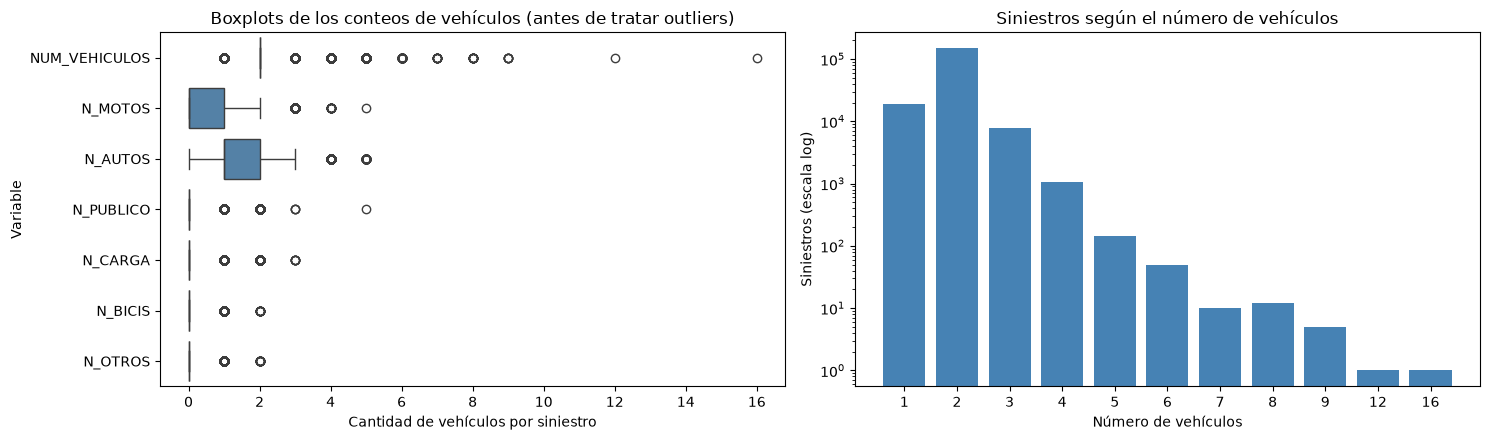

Casos con 9 o más vehículos:
        Código       Fecha       GRAVEDAD Numero vehículos                         Tipo de vehículos implicados
59358   155573   8/12/2016       Negativo               12                                                  NaN
62630   158846  23/12/2016       Negativo               16                                                  NaN
113026  209255  20/10/2017  Con lesionado                9  AUTOMOVIL,AUTOMOVIL,AUTOMOVIL,CAMIONETA,MOTOCICLETA
214023  310313  27/06/2019     Solo daños                9                                                  NaN
253472  349769  22/02/2020  Con lesionado                9    AUTOMOVIL,AUTOMOVIL,AUTOMOVIL,AUTOMOVIL,AUTOMOVIL
263552  360326  23/07/2020  Con lesionado                9    AUTOMOVIL,AUTOMOVIL,AUTOMOVIL,AUTOMOVIL,AUTOMOVIL
301554  400008  22/10/2021     Solo daños                9    AUTOMOVIL,AUTOMOVIL,AUTOMOVIL,AUTOMOVIL,AUTOMOVIL


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

sns.boxplot(data=df[COLS_CONTEO], orient="h", color="steelblue", ax=axes[0])
axes[0].set_title("Boxplots de los conteos de vehículos (antes de tratar outliers)")
axes[0].set_xlabel("Cantidad de vehículos por siniestro")
axes[0].set_ylabel("Variable")

conteo_num = df["NUM_VEHICULOS"].value_counts().sort_index()
axes[1].bar(conteo_num.index.astype(int).astype(str), conteo_num.values, color="steelblue")
axes[1].set_yscale("log")
axes[1].set_title("Siniestros según el número de vehículos")
axes[1].set_xlabel("Número de vehículos")
axes[1].set_ylabel("Siniestros (escala log)")
plt.tight_layout()
plt.show()

print("Casos con 9 o más vehículos:")
print(df.loc[df["NUM_VEHICULOS"] >= 9, ["Código", "Fecha", "GRAVEDAD", "Numero vehículos",
                                         "Tipo de vehículos implicados"]].to_string())

**Insight:** La regla IQR falla en estas variables. Casi todos los siniestros tienen exactamente 2 vehículos (Q1 = Q3 = 2,
IQR = 0), así que la regla marca como atípico cualquier siniestro con 1 o 3 vehículos (≈16% de los datos); en transporte
público, carga y bicicletas marca todos los casos en que ese vehículo aparece. El Z-score marca los siniestros con 4 o más
vehículos, que son choques múltiples reales.

Decisión: se conservan todas las filas y solo se corrigen 2 valores imposibles.

- Los siniestros con 4 a 9 vehículos se quedan. Son choques en cadena (varios tienen la lista de vehículos completa y
  dejaron lesionados), y quitarlos eliminaría casos que importan para la gravedad. Su peso en los modelos se reduce en el
  Paso 8 con Yeo-Johnson.
- Los reportes con 12 y 16 vehículos se tratan como error de captura: son reportes "Negativo" (no se confirmó ningún
  siniestro), no tienen lista de vehículos y superan de lejos el máximo con lista (9). El número pasa a `NaN` y se imputa
  en el Paso 7 como cualquier otro faltante. La fila se conserva porque el resto del reporte es válido.

In [13]:
error_captura = (df["NUM_VEHICULOS"] > 9) & (df["GRAVEDAD"] == "Negativo") & (df["SIN_DATO_VEHICULOS"] == 1)
print(f"Valores corregidos como error de captura: {error_captura.sum()} → {df.loc[error_captura, 'NUM_VEHICULOS'].tolist()}")
df.loc[error_captura, "NUM_VEHICULOS"] = np.nan
print(f"Nuevo máximo de NUM_VEHICULOS: {df['NUM_VEHICULOS'].max():.0f}")

Valores corregidos como error de captura: 2 → [12.0, 16.0]
Nuevo máximo de NUM_VEHICULOS: 9


## Paso 6. Split train/test (antes de imputar y escalar)

Split 80/20 estratificado por gravedad. La clase "Con fallecido" es el 0,9% de los reportes, y sin estratificar podría
quedar con muy pocos casos en el conjunto de prueba. La partición se guarda en la columna `SPLIT` del parquet.

In [14]:
idx_train, idx_test = train_test_split(df.index, test_size=0.2, stratify=df["GRAVEDAD"], random_state=SEMILLA)
df["SPLIT"] = "train"
df.loc[idx_test, "SPLIT"] = "test"
es_train = df["SPLIT"] == "train"

proporciones = pd.crosstab(df["GRAVEDAD"], df["SPLIT"], normalize="columns").reindex(ORDEN_GRAVEDAD) * 100
print(f"Train: {es_train.sum():,} filas · Test: {(~es_train).sum():,} filas\n")
print("% de cada clase en train y test:")
print(proporciones.round(2))

Train: 296,796 filas · Test: 74,200 filas

% de cada clase en train y test:
SPLIT           test  train
GRAVEDAD                   
Negativo       66.34  66.34
Solo daños     19.95  19.95
Con lesionado  12.80  12.80
Con fallecido   0.91   0.91


## Paso 7. Manejo de valores nulos

La Fase A mostró que los faltantes dependen del año (el formulario cambió) y, en algunas columnas, del resultado del caso.
Por eso cada columna tiene su estrategia:

| Columna | % faltante | Tipo | Estrategia | Justificación |
|---|---|---|---|---|
| `NUM_VEHICULOS` | ≈52% | Numérica discreta, sesgada | Mediana (de train) | La distribución es asimétrica (asimetría ≈ 1, curtosis ≈ 12). Los choques múltiples suben la media a 1,95, un valor que no existe como conteo; la mediana (2) no se mueve con ellos y es un entero. |
| `N_MOTOS` … `N_OTROS` | ≈60% | Numéricas discretas, muy sesgadas | Mediana (de train) + indicador `SIN_DATO_VEHICULOS` | Mismo motivo. El indicador le dice al modelo qué filas tenían el dato y cuáles fueron imputadas. |
| `MEDIO_REPORTE` | ≈78% | Categórica nominal | "SIN REGISTRO" antes de mayo de 2021 · Moda (de train) desde mayo de 2021 | El campo apareció en el formulario en mayo de 2021. Rellenar los años anteriores con la moda inventaría unos 290 mil valores. Desde mayo de 2021 los faltantes son pocos y sueltos, y la moda es la estimación usual para una categórica. |
| `CLASE_ACCIDENTE` | ≈88% | Categórica nominal | Moda (de train) en 2024 · "SIN REGISTRO" en el resto | En 2024 el campo está casi completo (0,2% faltante). Antes de 2024 la falta depende del resultado: el 81% de los "Negativo" no tiene clase. Imputar "CHOQUE" borraría esa diferencia. |
| `TIPO_VIA` | ≈50% | Categórica nominal | "SIN REGISTRO" | La dirección no se capturó entre 2018 y 2020: falta por años completos. |

KNN no se usó. KNNImputer completa un valor con el de los vecinos más parecidos, pero aquí las columnas de vehículos
faltan juntas (sin lista tampoco hay conteos). Los vecinos solo se distinguirían por la fecha, que en la Fase A no tuvo
relación con los vehículos (Spearman ≈ 0). Calcular distancias sobre unas 300 mil filas de entrenamiento también es costoso,
y no hay motivo para esperar un resultado mejor que el de la mediana.

> Todas las medianas y modas se calculan con `SPLIT == "train"` y luego se aplican a train y test.

In [15]:
pct_antes = (df[["NUM_VEHICULOS"] + COLS_N + ["MEDIO_REPORTE", "CLASE_ACCIDENTE", "TIPO_VIA"]].isna().mean() * 100).round(1)

# --- Numéricas: mediana de train -------------------------------------------------------------------------------------
x_train = df.loc[es_train, "NUM_VEHICULOS"].dropna()
print(f"NUM_VEHICULOS en train → media {x_train.mean():.2f} · mediana {x_train.median():.0f} · "
      f"asimetría {x_train.skew():.2f} · curtosis {x_train.kurt():.1f}")

medianas = df.loc[es_train, ["NUM_VEHICULOS"] + COLS_N].median()
df[["NUM_VEHICULOS"] + COLS_N] = df[["NUM_VEHICULOS"] + COLS_N].fillna(medianas)
print("\nMedianas de train usadas para imputar:")
print(medianas.to_string())

# --- Medio de reporte: SIN REGISTRO antes de que existiera el campo, moda de train después ----------------------------
INICIO_MEDIO = pd.Timestamp("2021-05-01")
con_medio = df["FECHA"] >= INICIO_MEDIO
moda_medio = df.loc[es_train & con_medio, "MEDIO_REPORTE"].mode()[0]
df.loc[con_medio, "MEDIO_REPORTE"] = df.loc[con_medio, "MEDIO_REPORTE"].fillna(moda_medio)
df["MEDIO_REPORTE"] = df["MEDIO_REPORTE"].fillna("SIN REGISTRO")

# --- Clase de accidente: moda de train en 2024, SIN REGISTRO en el resto ----------------------------------------------
es_2024 = df["ANIO"] == 2024
moda_clase = df.loc[es_train & es_2024, "CLASE_ACCIDENTE"].mode()[0]
df.loc[es_2024, "CLASE_ACCIDENTE"] = df.loc[es_2024, "CLASE_ACCIDENTE"].fillna(moda_clase)
df["CLASE_ACCIDENTE"] = df["CLASE_ACCIDENTE"].fillna("SIN REGISTRO")

# --- Tipo de vía: categoría constante ---------------------------------------------------------------------------------
df["TIPO_VIA"] = df["TIPO_VIA"].fillna("SIN REGISTRO")

print(f"\nModa de MEDIO_REPORTE (train, desde may-2021): {moda_medio}")
print(f"Moda de CLASE_ACCIDENTE (train, 2024): {moda_clase}")

resumen_nulos = pd.DataFrame({"% faltante antes": pct_antes,
                              "% faltante después": (df[pct_antes.index].isna().mean() * 100).round(1)})
resumen_nulos

NUM_VEHICULOS en train → media 1.95 · mediana 2 · asimetría 0.95 · curtosis 12.4

Medianas de train usadas para imputar:
NUM_VEHICULOS    2.0
N_MOTOS          0.0
N_AUTOS          1.0
N_PUBLICO        0.0
N_CARGA          0.0
N_BICIS          0.0
N_OTROS          0.0



Moda de MEDIO_REPORTE (train, desde may-2021): LINEA 127
Moda de CLASE_ACCIDENTE (train, 2024): CHOQUE


,% faltante antes,% faltante después
NUM_VEHICULOS,52.4,0.0
N_MOTOS,59.9,0.0
N_AUTOS,59.9,0.0
N_PUBLICO,59.9,0.0
N_CARGA,59.9,0.0
N_BICIS,59.9,0.0
N_OTROS,59.9,0.0
MEDIO_REPORTE,77.7,0.0
CLASE_ACCIDENTE,87.7,0.0
TIPO_VIA,49.5,0.0


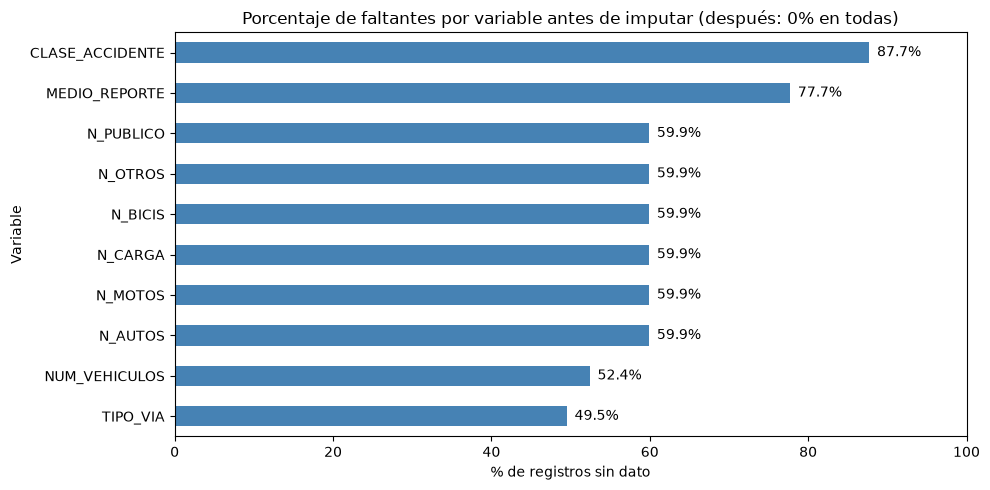

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
resumen_nulos["% faltante antes"].sort_values().plot.barh(color="steelblue", ax=ax, label="Antes de imputar")
ax.set_title("Porcentaje de faltantes por variable antes de imputar (después: 0% en todas)")
ax.set_xlabel("% de registros sin dato")
ax.set_ylabel("Variable")
ax.set_xlim(0, 100)
for i, v in enumerate(resumen_nulos["% faltante antes"].sort_values().values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center")
plt.tight_layout()
plt.show()

**Insight:** Ninguna variable queda con faltantes, pero no todas recibieron el mismo tratamiento. Las tres categóricas con
más del 50% de faltantes conservan "SIN REGISTRO" como categoría propia en lugar de recibir un valor inventado, porque esos
huecos coinciden con cambios del formulario de captura. Para la Secretaría de Movilidad, la categoría marca en qué periodos
se puede comparar cada indicador.

## Paso 8. Transformación de variables sesgadas

Se compara la asimetría (*skewness*) de cada conteo antes y después de dos transformaciones:

- log(1 + x) (`np.log1p`): admite ceros, no aprende parámetros y se interpreta fácil.
- Yeo-Johnson (`PowerTransformer`): busca para cada variable el exponente λ que más la acerca a una distribución normal;
  se ajusta solo con train.

In [17]:
pt = PowerTransformer(method="yeo-johnson", standardize=False).fit(df.loc[es_train, COLS_CONTEO])
yeo = pd.DataFrame(pt.transform(df[COLS_CONTEO]), columns=COLS_CONTEO, index=df.index)

asimetria = pd.DataFrame({
    "original": df.loc[es_train, COLS_CONTEO].skew(),
    "log1p": np.log1p(df.loc[es_train, COLS_CONTEO]).skew(),
    "yeo-johnson": yeo.loc[es_train].skew(),
}).round(2)
asimetria

,original,log1p,yeo-johnson
NUM_VEHICULOS,1.12,-1.54,0.50
N_MOTOS,2.21,1.84,1.63
N_AUTOS,0.75,-0.93,0.13
N_PUBLICO,5.54,5.14,4.96
N_CARGA,6.17,5.84,5.69
N_BICIS,17.13,16.81,16.68
N_OTROS,20.25,19.51,19.20


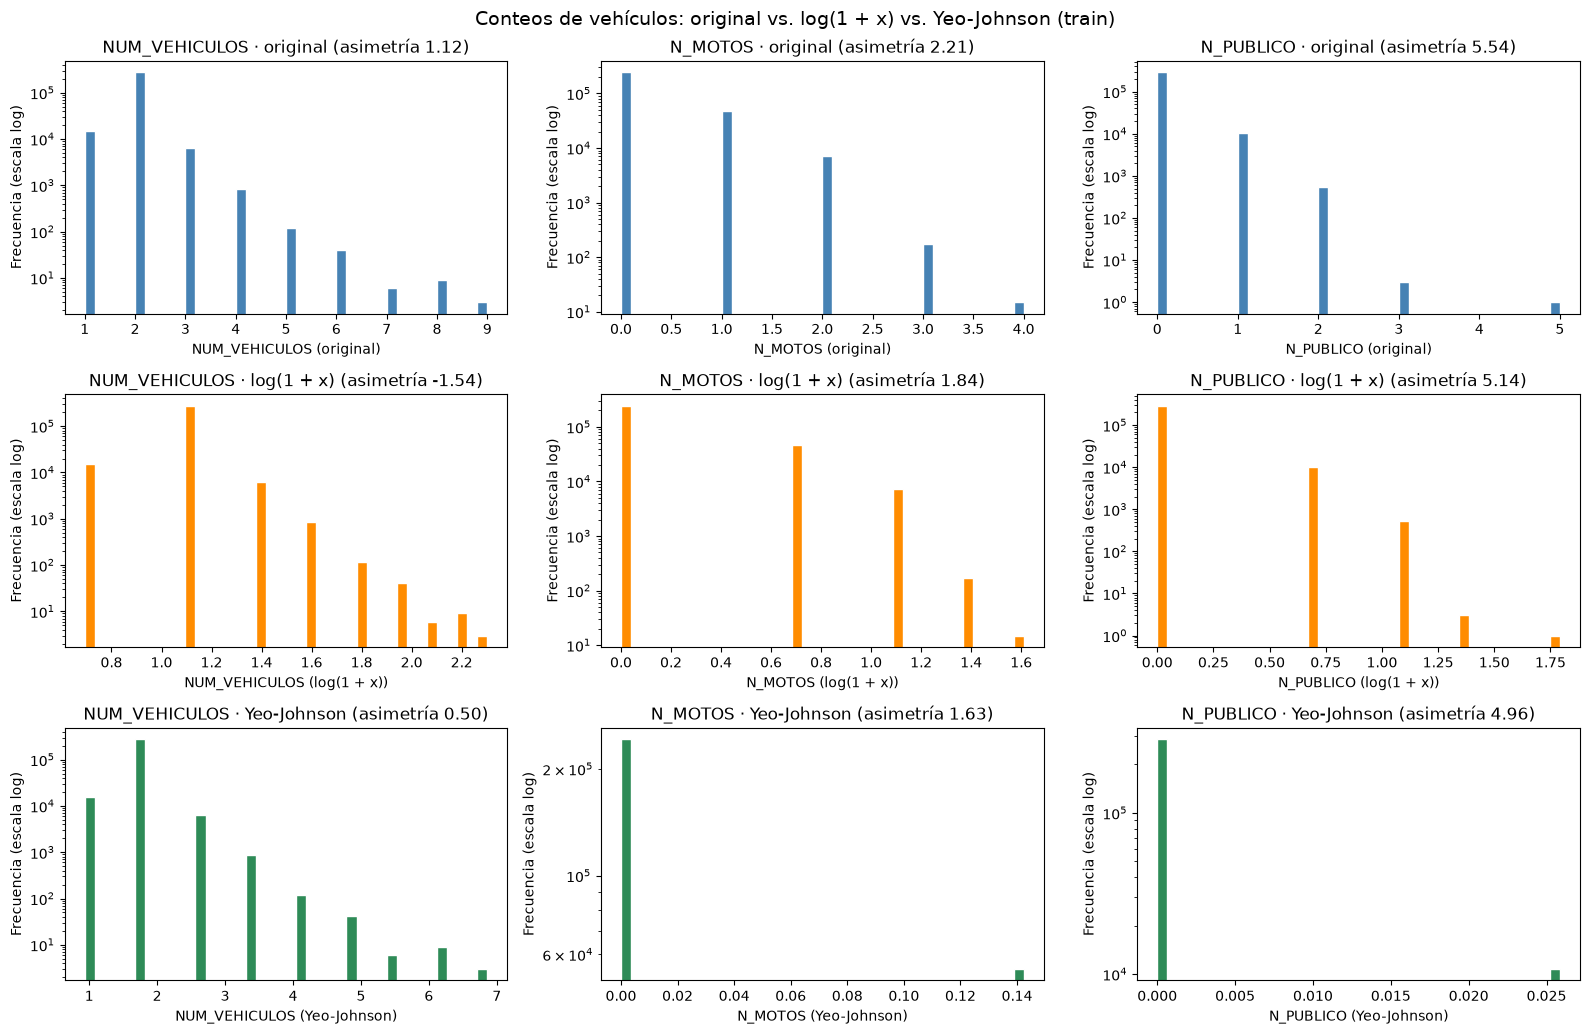

In [18]:
fig, axes = plt.subplots(3, 3, figsize=(16, 10.5))
versiones = [("original", lambda s: s, "steelblue"),
             ("log(1 + x)", np.log1p, "darkorange"),
             ("Yeo-Johnson", lambda s: yeo.loc[es_train, s.name], "seagreen")]
for j, col in enumerate(["NUM_VEHICULOS", "N_MOTOS", "N_PUBLICO"]):
    for i, (nombre, funcion, color) in enumerate(versiones):
        valores = funcion(df.loc[es_train, col])
        axes[i, j].hist(valores, bins=40, color=color, edgecolor="white")
        axes[i, j].set_yscale("log")
        axes[i, j].set_title(f"{col} · {nombre} (asimetría {valores.skew():.2f})")
        axes[i, j].set_xlabel(f"{col} ({nombre})")
        axes[i, j].set_ylabel("Frecuencia (escala log)")
plt.suptitle("Conteos de vehículos: original vs. log(1 + x) vs. Yeo-Johnson (train)", fontsize=14)
plt.tight_layout()
plt.show()

**Insight y decisión:** El logaritmo empeora `NUM_VEHICULOS`. Después de imputar, la mayoría de los valores es 2, y el log
comprime la cola derecha hasta invertir el sesgo: la asimetría pasa de +1,12 a −1,54 y el extremo pasa a ser el siniestro
de un solo vehículo. Yeo-Johnson deja la menor asimetría en todos los conteos (0,50 en `NUM_VEHICULOS`), así que se usa
Yeo-Johnson en las columnas con asimetría > 1 en train.

En bicicletas, carga y transporte público ninguna transformación logra simetría. Estas variables valen 0 en casi todas
las filas y registran un evento raro (el vehículo estuvo o no estuvo en el siniestro), y los modelos las van a usar así.

In [19]:
COLS_SESGADAS = asimetria.index[asimetria["original"].abs() > 1].tolist()
yeo_johnson = PowerTransformer(method="yeo-johnson", standardize=False).fit(df.loc[es_train, COLS_SESGADAS])
COLS_YJ = [f"YJ_{c}" for c in COLS_SESGADAS]
df[COLS_YJ] = yeo_johnson.transform(df[COLS_SESGADAS])

print("Columnas transformadas con Yeo-Johnson y su λ (ajustado con train):")
print(pd.Series(yeo_johnson.lambdas_, index=COLS_SESGADAS).round(3).to_string())

Columnas transformadas con Yeo-Johnson y su λ (ajustado con train):
NUM_VEHICULOS     0.822
N_MOTOS          -7.027
N_PUBLICO       -38.678
N_CARGA         -49.982
N_BICIS         -90.526
N_OTROS         -90.526


## Paso 9. Encoding de variables categóricas

| Variable | Tipo | Encoding | Por qué |
|---|---|---|---|
| `GRAVEDAD` (objetivo) | Ordinal | Ordinal 0–3 | Negativo < Solo daños < Con lesionado < Con fallecido: el número sigue el orden de gravedad. |
| `PERIODO_REGISTRO` | Ordinal | Ordinal 0–2 | Los periodos siguen el orden del tiempo. |
| `CLASE_ACCIDENTE` | Nominal | One-Hot | Choque, atropello y volcamiento no tienen orden. Con números, el modelo leería distancias que no existen (¿atropello = 2 × choque?). |
| `MEDIO_REPORTE` | Nominal | One-Hot | El canal de reporte no tiene orden. |
| `TIPO_VIA` | Nominal | One-Hot | El tipo de vía no tiene orden. |
| `DIA_SEMANA` | Nominal | One-Hot | En la Fase A, domingo y lunes fueron los días más letales. Con el día como número 0–6, un modelo lineal supondría que el riesgo sube o baja de lunes a domingo. |

One-Hot se hace con `pd.get_dummies(drop_first=True)`. Con *k* categorías bastan *k − 1* columnas: la que se elimina queda
como categoría de referencia, y así los modelos lineales no reciben columnas perfectamente colineales. Las categorías se
fijan en el código para que train y test tengan las mismas columnas y la referencia sea siempre la misma.

In [20]:
# --- Ordinal ---------------------------------------------------------------------------------------------------------
codificador = OrdinalEncoder(categories=[ORDEN_GRAVEDAD, ORDEN_PERIODO], dtype=int)
df[["GRAVEDAD_NUM", "PERIODO_NUM"]] = codificador.fit_transform(df[["GRAVEDAD", "PERIODO_REGISTRO"]])
print(pd.crosstab(df["GRAVEDAD"], df["GRAVEDAD_NUM"]).reindex(ORDEN_GRAVEDAD), "\n")

# --- One-Hot ---------------------------------------------------------------------------------------------------------
# La primera categoría de cada lista es la de referencia (la que elimina drop_first=True)
CATEGORIAS = {
    "CLASE_ACCIDENTE": ["SIN REGISTRO", "CHOQUE", "ATROPELLO", "VOLCAMIENTO", "CAIDA DE OCUPANTE", "OTRO", "NO APLICA"],
    "MEDIO_REPORTE": ["SIN REGISTRO", "LINEA 127", "CAD 123", "RADIO", "OTRO"],
    "TIPO_VIA": ["SIN REGISTRO", "CALLE", "CARRERA", "AVENIDA", "DIAGONAL/TRANSVERSAL", "VIA/CARRETERA",
                 "CENTRO MEDICO", "OTRO LUGAR"],
    "DIA_SEMANA": DIAS,
}
for col, categorias in CATEGORIAS.items():
    assert set(df[col]) <= set(categorias), f"{col} tiene categorías no previstas"
    df[col] = pd.Categorical(df[col], categories=categorias)

dummies = pd.get_dummies(df[list(CATEGORIAS)], drop_first=True, dtype=int)
dummies.columns = (dummies.columns.str.upper().str.replace(" ", "_").str.replace("/", "_")
                   .map(lambda c: unicodedata.normalize("NFKD", c).encode("ascii", "ignore").decode()))
df = df.join(dummies)
COLS_DUMMIES = list(dummies.columns)
print(f"Columnas One-Hot creadas: {len(COLS_DUMMIES)}")
print(COLS_DUMMIES)

GRAVEDAD_NUM        0      1      2     3
GRAVEDAD                                 
Negativo       246107      0      0     0
Solo daños          0  74029      0     0
Con lesionado       0      0  47500     0
Con fallecido       0      0      0  3360 



Columnas One-Hot creadas: 23
['CLASE_ACCIDENTE_CHOQUE', 'CLASE_ACCIDENTE_ATROPELLO', 'CLASE_ACCIDENTE_VOLCAMIENTO', 'CLASE_ACCIDENTE_CAIDA_DE_OCUPANTE', 'CLASE_ACCIDENTE_OTRO', 'CLASE_ACCIDENTE_NO_APLICA', 'MEDIO_REPORTE_LINEA_127', 'MEDIO_REPORTE_CAD_123', 'MEDIO_REPORTE_RADIO', 'MEDIO_REPORTE_OTRO', 'TIPO_VIA_CALLE', 'TIPO_VIA_CARRERA', 'TIPO_VIA_AVENIDA', 'TIPO_VIA_DIAGONAL_TRANSVERSAL', 'TIPO_VIA_VIA_CARRETERA', 'TIPO_VIA_CENTRO_MEDICO', 'TIPO_VIA_OTRO_LUGAR', 'DIA_SEMANA_MARTES', 'DIA_SEMANA_MIERCOLES', 'DIA_SEMANA_JUEVES', 'DIA_SEMANA_VIERNES', 'DIA_SEMANA_SABADO', 'DIA_SEMANA_DOMINGO']


## Paso 10. Estandarización y normalización

| Variables | Escalador | Por qué |
|---|---|---|
| `YJ_*` (conteos transformados) y `N_AUTOS` | Z-score (`StandardScaler`) | Después de Yeo-Johnson quedan más cerca de una campana. Z-score las lleva a media 0 y desviación 1, la escala que esperan KNN, SVM, la regresión logística y K-Means. |
| `ANIO`, `MES`, `PERIODO_NUM` | Min-Max (`MinMaxScaler`) → [0, 1] | Tienen un rango fijo y conocido (2016–2024, 1–12, 0–2) y no tienen outliers. Min-Max conserva las distancias relativas sin depender de la forma de la distribución. |
| Dummies One-Hot y `SIN_DATO_VEHICULOS` | Sin escalar | Ya están en {0, 1}. |

RobustScaler tampoco se usó: está pensado para variables con outliers y divide por el IQR. Aquí el IQR de casi todos los
conteos es 0 (Paso 5) y no tendría por qué dividir. Yeo-Johnson ya redujo el peso de los valores extremos.

Los escaladores se ajustan (`fit`) solo con train y se aplican (`transform`) a train y test.

In [21]:
COLS_ZSCORE = [f"YJ_{c}" if c in COLS_SESGADAS else c for c in COLS_CONTEO]
COLS_MINMAX = ["ANIO", "MES", "PERIODO_NUM"]

escalado = df.copy()
z_score = StandardScaler().fit(df.loc[es_train, COLS_ZSCORE])
min_max = MinMaxScaler().fit(df.loc[es_train, COLS_MINMAX])
escalado[COLS_ZSCORE] = z_score.transform(df[COLS_ZSCORE])
escalado[COLS_MINMAX] = min_max.transform(df[COLS_MINMAX])

control = escalado.groupby("SPLIT")[COLS_ZSCORE + COLS_MINMAX].agg(["mean", "std", "min", "max"]).T.round(3)
control.unstack(level=1)

SPLIT              test                        train                      
                   mean    std    min     max   mean    std    min     max
YJ_NUM_VEHICULOS  0.002  1.002 -3.334  20.462 -0.000  1.000 -3.334  20.462
YJ_N_MOTOS        0.002  1.002 -0.475   2.125  0.000  1.000 -0.475   2.125
N_AUTOS           0.008  1.002 -2.112   7.820  0.000  1.000 -2.112   7.820
YJ_N_PUBLICO     -0.002  0.995 -0.194   5.158  0.000  1.000 -0.194   5.158
YJ_N_CARGA       -0.000  0.999 -0.171   5.863 -0.000  1.000 -0.171   5.863
YJ_N_BICIS       -0.003  0.978 -0.060  16.743 -0.000  1.000 -0.060  16.743
YJ_N_OTROS       -0.000  0.998 -0.052  19.247  0.000  1.000 -0.052  19.247
ANIO              0.357  0.284  0.000   1.000  0.357  0.284  0.000   1.000
MES               0.505  0.317  0.000   1.000  0.505  0.317  0.000   1.000
PERIODO_NUM       0.211  0.320  0.000   1.000  0.211  0.320  0.000   1.000

Lectura de la tabla: en train las variables Z-score quedan con media 0 y desviación 1, y las Min-Max entre 0 y 1. En test
los valores se acercan a esos pero no son idénticos, porque los escaladores no vieron las filas de prueba. Con datos
nuevos va a pasar lo mismo.

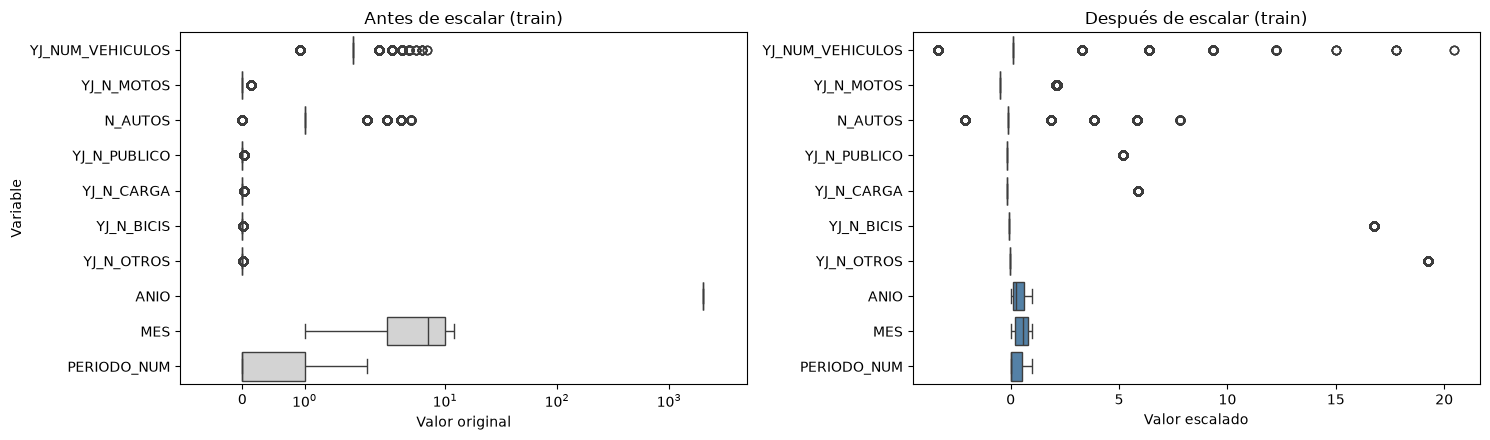

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=df.loc[es_train, COLS_ZSCORE + COLS_MINMAX], orient="h", color="lightgray", ax=axes[0])
axes[0].set_title("Antes de escalar (train)")
axes[0].set_xlabel("Valor original")
axes[0].set_ylabel("Variable")
axes[0].set_xscale("symlog")
axes[0].set_xlim(-1, 5000)

sns.boxplot(data=escalado.loc[es_train, COLS_ZSCORE + COLS_MINMAX], orient="h", color="steelblue", ax=axes[1])
axes[1].set_title("Después de escalar (train)")
axes[1].set_xlabel("Valor escalado")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Insight:** Antes de escalar, el año (≈2020) es unas mil veces más grande que un conteo de bicicletas (0 o 1), y un
modelo basado en distancias como KNN o K-Means decidiría casi solo por el año. Después del escalado las variables quedan
en rangos comparables.

## Paso 11. Validación final y guardado

Columnas originales que no pasan al dataset de modelado:

| Columna original | Motivo |
|---|---|
| `Código` | Identificador. Se conserva como `CODIGO` para rastrear cada reporte, pero no entra como variable predictiva. |
| `Fecha` | Reemplazada por `FECHA`, `ANIO`, `MES`, `DIA_SEMANA` y `PERIODO_REGISTRO`. |
| `Tipo confirmado` | Reemplazada por `GRAVEDAD` / `GRAVEDAD_NUM` (variable objetivo). |
| `Tipo confirmado.1` | Fuga de datos: describe el resultado del caso ("Arreglo formal", "Inspección a cadáver", "Muerto en la vía"…), es decir, la variable objetivo con otras palabras. |
| `Tipo clase de accidente.1` | Copia exacta de `Tipo clase de accidente`. |
| `Dirección reporte` | Texto libre (65 mil valores); entra como `TIPO_VIA`. |
| `Medio de reporte`, `Numero vehículos`, `Tipo de vehículos implicados` | Reemplazadas por `MEDIO_REPORTE`, `NUM_VEHICULOS` y `N_*`. |

El resultado se guarda en `datos_limpios.parquet`: datos imputados, codificados, transformados y escalados, con la
columna `SPLIT` que indica a qué partición pertenece cada reporte.

In [23]:
COLS_ID = ["CODIGO", "FECHA", "SPLIT"]
COLS_OBJETIVO = ["GRAVEDAD", "GRAVEDAD_NUM"]
COLS_FEATURES = COLS_ZSCORE + COLS_MINMAX + ["SIN_DATO_VEHICULOS"] + COLS_DUMMIES

escalado["CODIGO"] = escalado["Código"]
escalado["GRAVEDAD"] = escalado["GRAVEDAD"].astype(str)
limpio = escalado[COLS_ID + COLS_OBJETIVO + COLS_FEATURES].reset_index(drop=True)

# --- Validaciones ----------------------------------------------------------------------------------------------------
assert limpio.notna().all().all(), "Quedan valores nulos"
assert limpio["CODIGO"].is_unique, "Hay reportes repetidos"
assert limpio[COLS_FEATURES].dtypes.map(pd.api.types.is_numeric_dtype).all(), "Hay features no numéricas"
assert set(limpio["GRAVEDAD"]) == set(ORDEN_GRAVEDAD)
print("Validación OK: sin nulos, un reporte por fila, features numéricas y 4 clases de gravedad")
print(f"\nDataset limpio: {limpio.shape[0]:,} filas × {limpio.shape[1]} columnas "
      f"({len(COLS_FEATURES)} features + {len(COLS_ID)} de control + {len(COLS_OBJETIVO)} objetivo)")
print(limpio["SPLIT"].value_counts().to_string())

limpio.to_parquet("datos_limpios.parquet", index=False)
print("\nGuardado: datos_limpios.parquet")
limpio.head()

Validación OK: sin nulos, un reporte por fila, features numéricas y 4 clases de gravedad

Dataset limpio: 370,996 filas × 39 columnas (34 features + 3 de control + 2 objetivo)
SPLIT
train    296796
test      74200



Guardado: datos_limpios.parquet


,CODIGO,FECHA,SPLIT,GRAVEDAD,GRAVEDAD_NUM,YJ_NUM_VEHICULOS,YJ_N_MOTOS,N_AUTOS,YJ_N_PUBLICO,YJ_N_CARGA,...,TIPO_VIA_DIAGONAL_TRANSVERSAL,TIPO_VIA_VIA_CARRETERA,TIPO_VIA_CENTRO_MEDICO,TIPO_VIA_OTRO_LUGAR,DIA_SEMANA_MARTES,DIA_SEMANA_MIERCOLES,DIA_SEMANA_JUEVES,DIA_SEMANA_VIERNES,DIA_SEMANA_SABADO,DIA_SEMANA_DOMINGO
0,96159,2016-01-01,test,Solo daños,1,0.082791,2.104897,-2.112221,-0.193859,-0.170571,...,0,0,0,0,0,0,0,1,0,0
1,96160,2016-01-01,train,Negativo,0,0.082791,-0.474507,-0.125850,-0.193859,-0.170571,...,0,0,0,0,0,0,0,1,0,0
2,96161,2016-01-01,train,Con lesionado,2,0.082791,2.104897,-2.112221,-0.193859,-0.170571,...,0,0,0,0,0,0,0,1,0,0
3,96162,2016-01-01,train,Con lesionado,2,-3.333620,2.104897,-2.112221,-0.193859,-0.170571,...,0,0,0,0,0,0,0,1,0,0
4,96163,2016-01-01,train,Negativo,0,0.082791,-0.474507,-0.125850,-0.193859,-0.170571,...,0,0,0,0,0,0,0,1,0,0


In [24]:
# Verificación: el archivo guardado se puede leer y conserva tipos y tamaño
verificado = pd.read_parquet("datos_limpios.parquet")
print(f"Leído de nuevo: {verificado.shape[0]:,} × {verificado.shape[1]}")
print(verificado.dtypes.value_counts().to_string())

Leído de nuevo: 370,996 × 39
int64             25
float64           10
str                3
datetime64[us]     1


---

## Pasos seguidos y justificación de cada decisión

Esta sección es el documento breve de la Fase B: cada fila resume un paso del notebook y el motivo de la elección.

| Paso | Decisión | Justificación |
|---|---|---|
| Duplicados | Se eliminan 4 duplicados exactos y la fila vacía | Cada duplicado es un reporte cargado dos veces. |
| Objetivo | Se eliminan las 2 filas sin gravedad; la gravedad nunca se imputa | Imputarla sería inventar la respuesta. |
| Texto | Diccionario por columna | Clase: 14 variantes → 6. Medio: 17 → 4. Vehículos: 54 tipos → 6 grupos. |
| Nulos numéricos | Mediana de train + indicador | Conteos sesgados; la mediana no se mueve con los extremos y es un entero. |
| Nulos categóricos | "SIN REGISTRO" donde el campo no existía · Moda de train donde los faltantes son sueltos | Los faltantes dependen del periodo y del resultado (Fase A). |
| Outliers | Se conservan; solo se corrigen 2 valores imposibles (12 y 16 vehículos) | Con IQR = 0 la regla IQR marca casos normales; los choques múltiples son reales. |
| Sesgo | Yeo-Johnson (λ ajustado con train) en conteos con asimetría > 1 | log(1 + x) invertía el sesgo de `NUM_VEHICULOS` (+1,12 → −1,54); Yeo-Johnson lo bajó a 0,50. |
| Encoding | Ordinal: gravedad y periodo · One-Hot (`drop_first=True`): clase, medio, vía, día | Solo las variables con orden reciben números ordenados. |
| Escalado | Z-score: conteos · Min-Max: año, mes, periodo · ajustados solo con train | Rangos comparables para los modelos de distancia, sin fuga de datos. |

### Notas para la Fase C

1. Usar la columna `SPLIT` para separar train y test (`df[df.SPLIT == "train"]`). La imputación y el escalado se
   ajustaron con esa partición; otro `train_test_split` sobre el parquet escalado mezclaría filas que ya influyeron en
   esos cálculos.
2. "Con fallecido" es el 0,9% de los reportes. Hay que reportar Recall y F1 por clase, no solo Accuracy.
3. `SIN_DATO_VEHICULOS`, `CLASE_ACCIDENTE_*` antes de 2024 y `TIPO_VIA_CENTRO_MEDICO` dependen de cómo se registró el
   resultado (Fase A). Sirven para explicar la gravedad entre siniestros confirmados (`GRAVEDAD_NUM > 0`). Para predecir si
   un reporte será "Negativo", conviene excluirlas o comparar el desempeño con y sin ellas.